In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Uncomment and run this block in your notebook
from google.colab import files
uploaded = files.upload()

Saving hot-coffee.csv to hot-coffee.csv


In [ ]:
df = pd.read_csv('hot-coffee.csv')

In [ ]:
#Now let's view the first 4 rows
df.head(4)

,time,insulated with lid,insulated,ceramic
0,5,146.6,135.5,128.8
1,10,141.0,118.9,113.9
2,15,136.7,107.9,102.5
3,20,132.5,100.5,95.9


In [ ]:
# 1. Shape of the dataset (rows, columns)
print(f"Dataset Shape: {df.shape}")

# 2. Column names and non-null counts / data types
print("\n--- Data Info ---")
df.info()
# 3. check for missingn value
print(df.isnull().sum())

Dataset Shape: (11, 4)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   time                11 non-null     int64  
 1   insulated with lid  11 non-null     float64
 2   insulated           11 non-null     float64
 3   ceramic             11 non-null     float64
dtypes: float64(3), int64(1)
memory usage: 484.0 bytes
time                  0
insulated with lid    0
insulated             0
ceramic               0
dtype: int64


In [ ]:
#Generate Summary Statistics
summary_stats = df.describe()
print(summary_stats)

            time  insulated with lid   insulated     ceramic
count  11.000000           11.000000   11.000000   11.000000
mean   30.000000          128.018182   96.827273   92.518182
std    16.583124           10.146311   17.619029   16.571833
min     5.000000          115.700000   79.700000   76.600000
25%    17.500000          120.050000   84.150000   80.700000
50%    30.000000          125.600000   90.800000   86.300000
75%    42.500000          134.600000  104.200000   99.200000
max    55.000000          146.600000  135.500000  128.800000


In [ ]:
import pandas as pd

# Initialize a new DataFrame for differences
df_diff = pd.DataFrame({'time': df['time']})

# Loop through each cup type column and calculate the difference from the previous row
for col in ['insulated with lid', 'insulated', 'ceramic']:
    df_diff[f'{col}_drop'] = df[col].diff()

# Corrected the column name from 'insulated no lid_drop' to 'insulated with lid_drop'
print(df_diff[['time', 'insulated with lid_drop', 'insulated_drop', 'ceramic_drop']])

    time  insulated with lid_drop  insulated_drop  ceramic_drop
0      5                      NaN             NaN           NaN
1     10                     -5.6           -16.6         -14.9
2     15                     -4.3           -11.0         -11.4
3     20                     -4.2            -7.4          -6.6
4     25                     -3.5            -5.9          -5.4
5     30                     -3.4            -3.8          -4.2
6     35                     -2.2            -3.2          -2.7
7     40                     -1.8            -2.2          -2.0
8     45                     -3.1            -2.5          -1.8
9     50                     -0.9            -1.6          -1.6
10    55                     -1.9            -1.6          -1.6


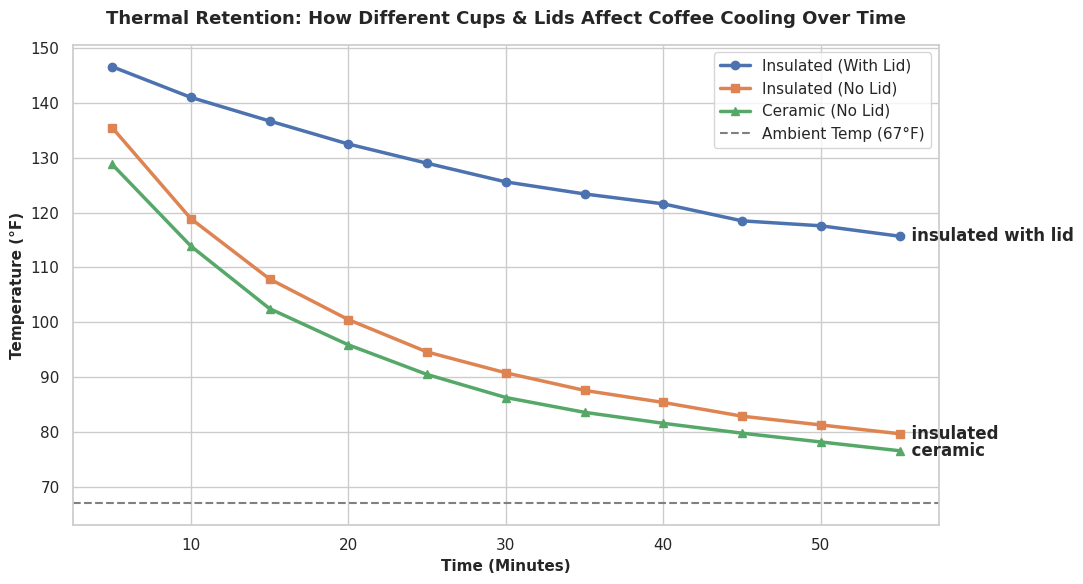

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Plot temperature curves for each cup type (using exact column names)
plt.plot(df['time'], df['insulated with lid'], marker='o', linewidth=2.5, label='Insulated (With Lid)')
plt.plot(df['time'], df['insulated'], marker='s', linewidth=2.5, label='Insulated (No Lid)')
plt.plot(df['time'], df['ceramic'], marker='^', linewidth=2.5, label='Ceramic (No Lid)')

# Add ambient room temperature baseline (67°F)
plt.axhline(y=67, color='gray', linestyle='--', linewidth=1.5, label='Ambient Temp (67°F)')

# Add clean titles and axis labels
plt.title('Thermal Retention: How Different Cups & Lids Affect Coffee Cooling Over Time', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Time (Minutes)', fontsize=11, fontweight='bold')
plt.ylabel('Temperature (°F)', fontsize=11, fontweight='bold')

# Use our helper function to label the lines at the end
def add_end_labels(df, x, column_names, alpha=1, fontweight='normal'):
    for column_name in column_names:
        y = df[column_name].iloc[-1]
        label = f'  {column_name}'
        plt.text(x, y, label, va="center", alpha=alpha, fontweight=fontweight)

add_end_labels(df, df['time'].iloc[-1], ['insulated with lid', 'insulated', 'ceramic'], fontweight='bold')

# Show legend and grid layout
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

# Save the figure so you can add it to your GitHub repository
plt.savefig('coffee_cooling_analysis.png', dpi=300)
plt.show()

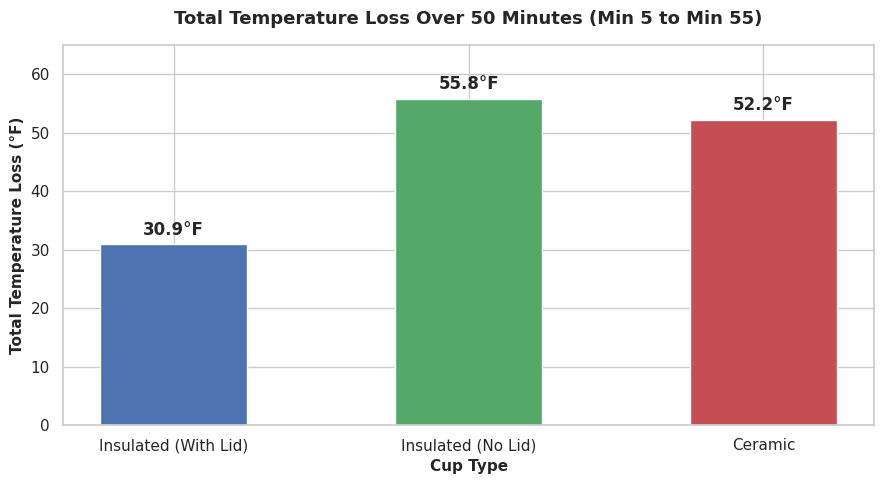

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Ensure our dataframe is loaded (if running in a fresh cell)
# df = pd.read_csv('hot-coffee.csv')

# 2. Define our labels and calculate total temperature drop (from minute 5 to minute 55)
cup_labels = ['Insulated (With Lid)', 'Insulated (No Lid)', 'Ceramic']
column_names = ['insulated with lid', 'insulated', 'ceramic']

total_drops = [
    df[col].iloc[0] - df[col].iloc[-1] for col in column_names
]

# 3. Set up the professional plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# 4. Create the bar chart with custom colors
bars = plt.bar(cup_labels, total_drops, color=['#4c72b0', '#55a868', '#c44e52'], width=0.5)

# 5. Add titles and axis labels
plt.title('Total Temperature Loss Over 50 Minutes (Min 5 to Min 55)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Cup Type', fontsize=11, fontweight='bold')
plt.ylabel('Total Temperature Loss (°F)', fontsize=11, fontweight='bold')

# 6. Add exact value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_width() / 2.0 + bar.get_x(), yval + 1, f'{yval:.1f}°F',
             ha='center', va='bottom', fontweight='bold')

# Set y-axis limit to give room for the text labels
plt.ylim(0, 65)

plt.tight_layout()

# 7. Save the chart as an image for your GitHub repository
plt.savefig('total_temperature_drop.png', dpi=300)
plt.show()

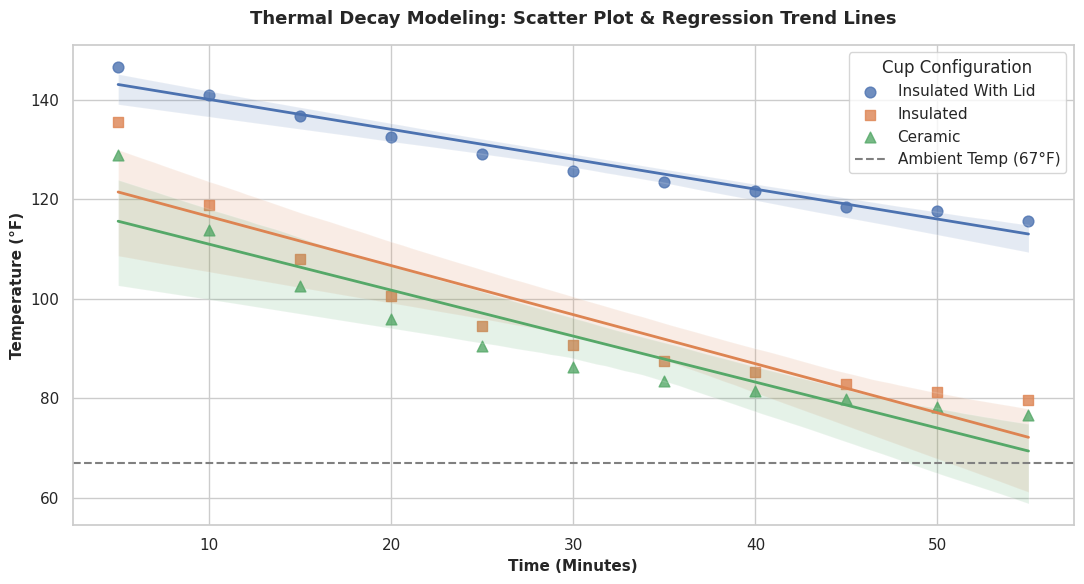

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set up the plotting theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# 2. Define our cup types and matching markers (corrected column name)
cup_types = ['insulated with lid', 'insulated', 'ceramic']
markers = ['o', 's', '^']

# 3. Loop through and plot scatter points with built-in regression trend lines
for cup, marker in zip(cup_types, markers):
    sns.regplot(
        data=df,
        x='time',
        y=cup,
        marker=marker,
        label=cup.title(),
        scatter_kws={'s': 60, 'alpha': 0.8},  # size and transparency of dots
        line_kws={'linewidth': 2}             # thickness of the trend line
    )

# 4. Add ambient room temperature baseline (67°F)
plt.axhline(y=67, color='gray', linestyle='--', linewidth=1.5, label='Ambient Temp (67°F)')

# 5. Add clean titles and axis labels
plt.title('Thermal Decay Modeling: Scatter Plot & Regression Trend Lines', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Time (Minutes)', fontsize=11, fontweight='bold')
plt.ylabel('Temperature (°F)', fontsize=11, fontweight='bold')

# 6. Show legend and clean layout
plt.legend(title='Cup Configuration', loc='upper right', frameon=True)
plt.tight_layout()

# 7. Save the figure for your GitHub repository
plt.savefig('cooling_regression_analysis.png', dpi=300)
plt.show()

### 📊 Statistical Modeling: Thermal Decay & Regression Analysis

**Analytical Objective:**
While our initial line plot tracked continuous time-series trajectories, this scatter plot pairs **raw experimental observations** with **statistical modeling** to examine cooling behavior.

**Key Technical Takeaways:**
* **Scatter Points:** Represent the discrete, real-world temperature measurements recorded at each 5-minute interval.
* **Regression Trend Lines:** Fit a statistical model through the data points to visualize the overall rate of heat dissipation and linear trends across each container type.
* **Insight:** By contrasting individual data dispersion against the fitted trend lines, we can clearly observe how container design (insulation walls vs. lids) alters thermal retention efficiency over a 50-minute window.

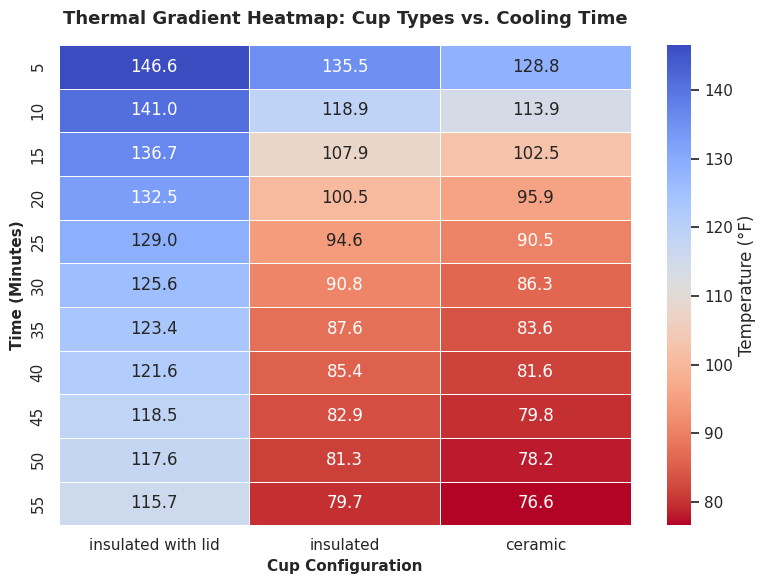

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare data for the heatmap by setting 'time' as the row index
df_heatmap = df.set_index('time')

# 2. Set up the plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# 3. Create the heatmap
# 'coolwarm_r' maps high temps to warm colors (red) and low temps to cool colors (blue)
sns.heatmap(
    df_heatmap,
    annot=True,              # Prints the exact temperature number inside each box
    fmt=".1f",               # Formats numbers to 1 decimal place
    cmap="coolwarm_r",       # Color palette (red = hot, blue = cool)
    cbar_kws={'label': 'Temperature (°F)'},
    linewidths=0.5           # Adds clean grid lines between the boxes
)

# 4. Add titles and axis labels
plt.title('Thermal Gradient Heatmap: Cup Types vs. Cooling Time', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Cup Configuration', fontsize=11, fontweight='bold')
plt.ylabel('Time (Minutes)', fontsize=11, fontweight='bold')

plt.tight_layout()

# 5. Save the figure for your GitHub repository
plt.savefig('temperature_heatmap.png', dpi=300)
plt.show()